# 06 – Where should charging investment go?

**Business question 4.** Which local authorities should be prioritised for public charging investment?

Notebooks 04 and 05 showed that no single measure is enough:
- The biggest *current* gaps (EVs per charger) are in suburban areas where many people can charge on their own driveway.
- Deprived and dense areas look well served today only because they have few EVs yet.

So the priority score combines **three indicators**, each pointing to a different reason to invest:

| Indicator | What it measures | Why it matters |
| --- | --- | --- |
| Private BEVs per public charger (July 2026) | today's gap | pressure on the existing network |
| Households in flats or terraced houses (Census 2021) | how many people are unlikely to have a driveway | these drivers depend on public charging |
| Growth in private BEVs, June 2025 → June 2026 | how fast demand is rising | where the gap will be next |

**Scoring method (simple and transparent):**
1. Each indicator is converted to a **percentile rank** from 0 to 1. For example, 0.9 means the area is higher than 90% of local authorities. Ranks are used instead of raw values so one extreme area (e.g. North East Derbyshire with 50 EVs per charger) cannot dominate.
2. The **priority score** is the simple average of the three ranks. All three get equal weight, because there is no evidence to say one matters more.

This is the same as `PERCENTRANK` and `AVERAGE` in Excel.

**Scope:** England and Wales (318 local authorities), because the census housing table covers only these two nations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. Build the three indicators

In [2]:
la = pd.read_csv(PROCESSED + "la_analysis_table.csv")
housing = pd.read_csv(PROCESSED + "housing_by_la.csv")
vehicles = pd.read_csv(PROCESSED + "vehicles_by_la.csv")

# Private battery electric cars one year ago and now
cars = vehicles[(vehicles["body_type"] == "Cars") & vehicles["quarter"].isin(["2025 Q2", "2026 Q2"])]
growth = cars.pivot(index="la_code", columns="quarter", values="bev_private")
growth["bev_private_growth"] = (growth["2026 Q2"] / growth["2025 Q2"] - 1) * 100

# Inner join keeps England and Wales only (the census covers these two nations)
priority = (
    la.merge(housing, on="la_code")
    .merge(growth[["bev_private_growth"]], on="la_code")
)
priority["no_driveway_share"] = (priority["flats"] + priority["terraced"]) / priority["households"] * 100

INDICATORS = ["bev_private_per_charger", "no_driveway_share", "bev_private_growth"]
print(priority.shape)
priority[INDICATORS].describe().round(1)

(318, 21)


,bev_private_per_charger,no_driveway_share,bev_private_growth
count,318.0,318.0,318.0
mean,11.8,42.2,49.8
std,6.6,17.1,14.8
min,0.4,14.6,0.0
25%,7.3,30.3,41.1
50%,11.3,38.4,51.2
75%,15.1,50.8,60.6
max,50.3,99.6,82.8


In the typical local authority, 38% of households live in a flat or terraced house, and private battery electric cars grew by about half in a year.

The indicators are only loosely related to each other (see below). Areas with many flats tend to have *smaller* gaps today, which is exactly why one measure alone would give a one-sided picture.

In [3]:
# Rank correlation between the indicators (Spearman, as in notebook 05)
priority[INDICATORS].rank().corr().round(2)

,bev_private_per_charger,no_driveway_share,bev_private_growth
bev_private_per_charger,1.00,-0.51,0.27
no_driveway_share,-0.51,1.00,-0.34
bev_private_growth,0.27,-0.34,1.00


## 2. Priority score

In [4]:
# Percentile rank: 0 = lowest local authority, 1 = highest
RANKS = ["rank_gap", "rank_no_driveway", "rank_growth"]
for rank_column, indicator in zip(RANKS, INDICATORS):
    priority[rank_column] = priority[indicator].rank(pct=True)

priority["priority_score"] = priority[RANKS].mean(axis=1)
priority = priority.sort_values("priority_score", ascending=False).reset_index(drop=True)
priority.index = priority.index + 1

priority.head(20)[["la_name", "region", "bev_private", "chargers"] + INDICATORS + ["priority_score"]].round(2)

,la_name,region,bev_private,chargers,bev_private_per_charger,no_driveway_share,bev_private_growth,priority_score
1,Knowsley,North West,2283.0,92,24.82,41.64,82.79,0.85
2,Hyndburn,North West,747.0,50,14.94,59.58,69.00,0.84
3,Halton,North West,2068.0,88,23.50,44.31,66.51,0.83
4,Bolton,North West,3529.0,170,20.76,46.51,65.14,0.82
5,Tameside,North West,2391.0,142,16.84,49.30,65.81,0.81
6,Pendle,North West,829.0,63,13.16,60.72,63.19,0.77
7,North East Lincolnshire,Yorkshire and The Humber,1632.0,112,14.57,42.91,73.62,0.77
8,North Tyneside,North East,2983.0,133,22.43,45.77,58.17,0.77
9,Blackburn with Darwen,North West,1686.0,129,13.07,55.19,64.17,0.76
10,Nuneaton and Bedworth,West Midlands,1838.0,84,21.88,36.56,65.59,0.75


**Indicative size of the investment.** For each area, how many extra public chargers would bring it down to the typical (median) number of private EVs per charger? This is a rough, relative guide, not a forecast: the ratio only counts private cars, and it ignores future growth.

In [5]:
median_ratio = priority["bev_private_per_charger"].median()
# Chargers needed so that private BEVs / chargers = median; zero if already below the median
priority["extra_chargers_to_median"] = (priority["bev_private"] / median_ratio - priority["chargers"]).clip(lower=0).round()

top20 = priority.head(20)
print(f"Median: {median_ratio:.1f} private BEVs per charger")
print(f"Top 20 priority areas have {top20['chargers'].sum():,.0f} public chargers today")
print(f"About {top20['extra_chargers_to_median'].sum():,.0f} more would bring them to the median")

Median: 11.3 private BEVs per charger
Top 20 priority areas have 2,734 public chargers today
About 1,846 more would bring them to the median


## 3. Charts

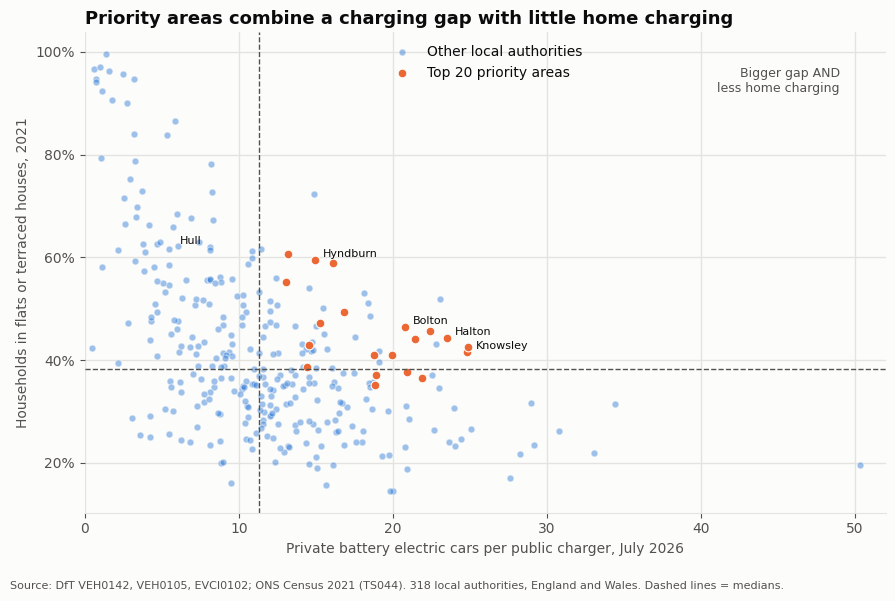

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
is_top = priority.index <= 20
ax.scatter(priority.loc[~is_top, "bev_private_per_charger"], priority.loc[~is_top, "no_driveway_share"],
           s=24, color=BLUE, alpha=0.45, edgecolor=SURFACE, linewidth=0.8, label="Other local authorities")
ax.scatter(priority.loc[is_top, "bev_private_per_charger"], priority.loc[is_top, "no_driveway_share"],
           s=40, color=ORANGE, edgecolor=SURFACE, linewidth=0.8, label="Top 20 priority areas")

# Median lines split the chart into four groups
ax.axvline(priority["bev_private_per_charger"].median(), color=TEXT_2, linewidth=1, linestyle="--")
ax.axhline(priority["no_driveway_share"].median(), color=TEXT_2, linewidth=1, linestyle="--")
ax.text(49, 97, "Bigger gap AND\nless home charging", ha="right", va="top", fontsize=9, color=TEXT_2)

for name in ["Knowsley", "Hyndburn", "Halton", "Bolton"]:
    row = priority[priority["la_name"] == name].iloc[0]
    ax.annotate(name, (row["bev_private_per_charger"], row["no_driveway_share"]),
                xytext=(6, 2), textcoords="offset points", fontsize=8, color=TEXT)
# Hull is not a priority area; labelled on the left as an example of a city with many terraces
hull = priority[priority["la_name"] == "Kingston upon Hull, City of"].iloc[0]
ax.annotate("Hull", (hull["bev_private_per_charger"], hull["no_driveway_share"]),
            xytext=(-6, 2), textcoords="offset points", ha="right", fontsize=8, color=TEXT)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=True)
ax.set_axisbelow(True)
ax.set_xlim(0, 52)
ax.set_title("Priority areas combine a charging gap with little home charging")
ax.set_xlabel("Private battery electric cars per public charger, July 2026")
ax.set_ylabel("Households in flats or terraced houses, 2021")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout(rect=(0, 0.04, 1, 1))
add_source(fig, "Source: DfT VEH0142, VEH0105, EVCI0102; ONS Census 2021 (TS044). 318 local authorities, England and Wales. Dashed lines = medians.")
fig.savefig(FIGURES + "10_priority_matrix.png", dpi=200)
plt.show()

**How to read this chart:** each dot is a local authority. Right = more EVs per public charger today; up = more households without a likely driveway. The dashed lines are the medians, so the **top-right** box holds areas that are above average on both. Orange dots are the 20 highest priority scores. The third indicator (growth) is not shown on the axes, which is why a few orange dots sit outside the top-right box.

**What it shows**
- The two measures pull in opposite directions: suburban areas (bottom right) have big gaps but mostly houses with driveways; cities like Hull (top left) have many terraces but already have plenty of chargers per EV.
- The priority areas sit in the **middle-right and upper part**: a clear charging gap *and* a large share of households likely to rely on public chargers.

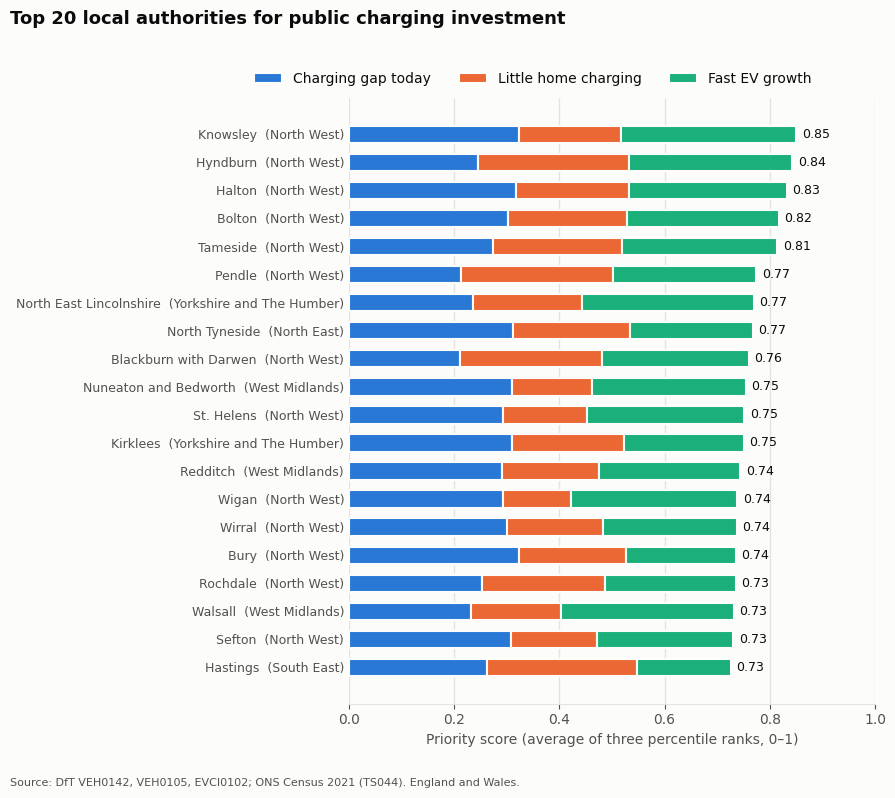

In [7]:
labels = top20["la_name"].str.replace(", City of", "") + "  (" + top20["region"] + ")"
parts = [
    ("rank_gap", "Charging gap today", BLUE),
    ("rank_no_driveway", "Little home charging", ORANGE),
    ("rank_growth", "Fast EV growth", AQUA),
]

fig, ax = plt.subplots(figsize=(9, 8))
y = range(len(top20))[::-1]
left = pd.Series(0.0, index=top20.index)
# Each indicator adds one third of its rank, so the bar length equals the priority score
for column, name, color in parts:
    width = top20[column] / 3
    ax.barh(list(y), width, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=name)
    left = left + width
for i, score in zip(y, top20["priority_score"]):
    ax.annotate(f"{score:.2f}", (score, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_yticks(list(y))
ax.set_yticklabels(labels, fontsize=9)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_axisbelow(True)
ax.set_xlabel("Priority score (average of three percentile ranks, 0–1)")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.35, 1.0))
fig.suptitle("Top 20 local authorities for public charging investment", x=0.01, ha="left", fontsize=13, fontweight="semibold")
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
add_source(fig, "Source: DfT VEH0142, VEH0105, EVCI0102; ONS Census 2021 (TS044). England and Wales.")
fig.savefig(FIGURES + "11_top20_priority_areas.png", dpi=200)
plt.show()

**How to read this chart:** the 20 areas with the highest priority score. Each bar is split into the three indicators, so you can see *why* an area ranks high. A long blue part means a big gap today, orange means many households without a driveway and green means fast EV growth.

**What it shows**
- **Most of the list is in the North West**, especially the boroughs around Manchester and Liverpool (Knowsley, Halton, Bolton, Tameside, Wigan, St Helens, Bury, Rochdale, Sefton, Wirral) and the east Lancashire towns (Hyndburn, Pendle, Blackburn with Darwen). These areas score well on all three indicators at the same time.
- The rest are towns in Yorkshire, the North East and the West Midlands, plus Hastings in the South East.
- None are in London: London already has the lowest number of EVs per charger in the country.

In [8]:
top50 = priority.head(50)
regions = pd.DataFrame({
    "local_authorities": priority.groupby("region").size(),
    "in_top_50": top50.groupby("region").size(),
}).fillna(0)
regions["share_in_top_50"] = regions["in_top_50"] / regions["local_authorities"] * 100
regions = regions.sort_values("share_in_top_50")
regions

,local_authorities,in_top_50,share_in_top_50
region,,,
London,33,0.0,0.000000
South West,27,0.0,0.000000
South East,64,6.0,9.375000
East of England,45,5.0,11.111111
East Midlands,35,4.0,11.428571
Wales,22,3.0,13.636364
North East,12,2.0,16.666667
West Midlands,30,5.0,16.666667
Yorkshire and The Humber,15,5.0,33.333333


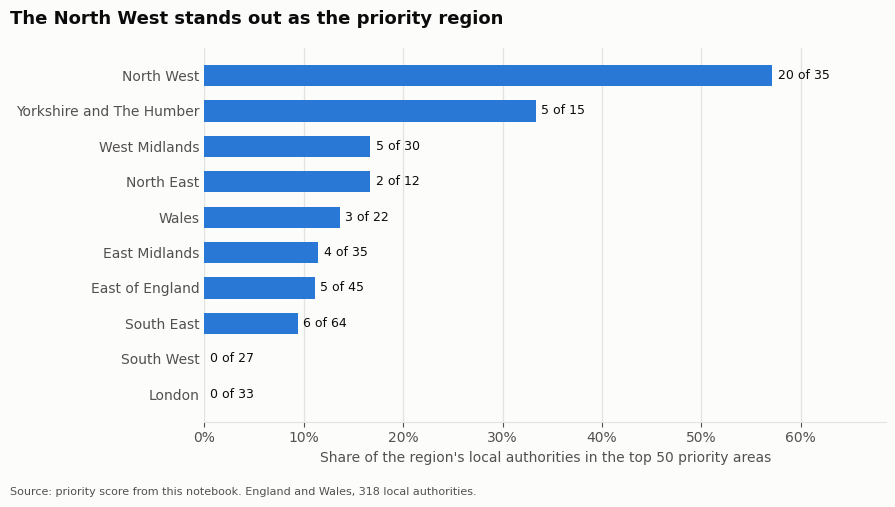

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(regions))
ax.barh(list(y), regions["share_in_top_50"], height=0.6, color=BLUE)
for i, (share, count, total) in enumerate(zip(regions["share_in_top_50"], regions["in_top_50"], regions["local_authorities"])):
    ax.annotate(f"{count:.0f} of {total:.0f}", (share, i), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXT)
ax.set_yticks(list(y))
ax.set_yticklabels(regions.index)
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, regions["share_in_top_50"].max() * 1.2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_axisbelow(True)
ax.set_xlabel("Share of the region's local authorities in the top 50 priority areas")
fig.suptitle("The North West stands out as the priority region", x=0.01, ha="left", fontsize=13, fontweight="semibold")
plt.tight_layout(rect=(0, 0.04, 1, 1))
add_source(fig, "Source: priority score from this notebook. England and Wales, 318 local authorities.")
fig.savefig(FIGURES + "12_priority_by_region.png", dpi=200)
plt.show()

**How to read this chart:** for each region, the share of its local authorities that are in the top 50 priority areas (the label gives the count). Regions have different numbers of local authorities, so the share is fairer than the count.

**What it shows:** **20 of the 35 North West local authorities** are in the top 50, far more than any other region. London and the South West have none. A regional programme in the North West would cover a large part of the priority list.

## 4. How robust is the ranking?

The equal weights are a choice. To test it, each indicator in turn is given **double weight**, and the new top 20 is compared with the original.

In [10]:
original_top20 = set(top20["la_code"])
checks = {}
for i, name in enumerate(["Gap counts double", "Home charging counts double", "Growth counts double"]):
    weights = [1, 1, 1]
    weights[i] = 2
    score = (priority[RANKS] * weights).sum(axis=1) / sum(weights)
    new_top20 = set(priority.loc[score.nlargest(20).index, "la_code"])
    checks[name] = len(new_top20 & original_top20)

pd.Series(checks, name="Areas still in the top 20 (out of 20)")

Gap counts double              18
Home charging counts double    12
Growth counts double           15
Name: Areas still in the top 20 (out of 20), dtype: int64

**Result:** with any indicator counting double, 12 to 18 of the 20 areas stay in the top 20. The core of the list, mainly the Greater Manchester and Merseyside boroughs, does not depend on the exact weights. The exact order further down should be read with care.

## 5. Save the ranking

The full ranking is saved as a CSV, so it can be opened in Excel, filtered and shared.

In [11]:
ranking = priority[["la_code", "la_name", "region", "bev_private", "chargers"] + INDICATORS
                   + ["priority_score", "extra_chargers_to_median"]].round(2)
ranking.index.name = "priority_rank"
ranking.to_csv("../outputs/priority_ranking.csv")
ranking.head(10)

,la_code,la_name,region,bev_private,chargers,bev_private_per_charger,no_driveway_share,bev_private_growth,priority_score,extra_chargers_to_median
priority_rank,,,,,,,,,,
1,E08000011,Knowsley,North West,2283.0,92,24.82,41.64,82.79,0.85,110.0
2,E07000120,Hyndburn,North West,747.0,50,14.94,59.58,69.00,0.84,16.0
3,E06000006,Halton,North West,2068.0,88,23.50,44.31,66.51,0.83,95.0
4,E08000001,Bolton,North West,3529.0,170,20.76,46.51,65.14,0.82,142.0
5,E08000008,Tameside,North West,2391.0,142,16.84,49.30,65.81,0.81,69.0
6,E07000122,Pendle,North West,829.0,63,13.16,60.72,63.19,0.77,10.0
7,E06000012,North East Lincolnshire,Yorkshire and The Humber,1632.0,112,14.57,42.91,73.62,0.77,32.0
8,E08000022,North Tyneside,North East,2983.0,133,22.43,45.77,58.17,0.77,130.0
9,E06000008,Blackburn with Darwen,North West,1686.0,129,13.07,55.19,64.17,0.76,20.0


## Answer to question 4 and recommendations

**Where to invest first**
1. **The North West, especially Greater Manchester, Merseyside and east Lancashire** (e.g. Knowsley, Hyndburn, Halton, Bolton, Tameside, Pendle, Wigan, St Helens, Bury). These areas combine an above-average gap today, a high share of terraced and flat households who cannot charge at home, and fast EV growth. 20 of the region's 35 local authorities are in the national top 50.
2. **Industrial towns in the North and Midlands** with the same pattern: North East Lincolnshire, Kirklees, Walsall, Redditch, Nuneaton and Bedworth, North Tyneside.
3. **Type of charger:** in these areas the need is mainly **on-street and neighbourhood charging** (lamp-post and residential hubs) for households without a driveway, rather than rapid chargers only.

**Size:** bringing the top 20 areas to the national median would need roughly **1,800 extra public chargers**, on top of the 2,700 they have today. This is an indicative figure (private cars only, no future growth), useful to compare areas, not a business case.

**What not to prioritise:** inner London (already the best served) and rural areas with mostly detached houses (Powys, Cotswold, North Norfolk), where home charging covers most needs. Rural areas may still need rapid chargers on main roads, which this analysis does not cover.

**Limitations**
- Company cars cannot be placed where their drivers live, so all local ratios use private cars only (about half of battery electric cars).
- Flats and terraced houses are a proxy for "no driveway". Some terraces have parking, and some detached houses do not.
- The census is from 2021; housing changes slowly, so this is acceptable.
- Charger counts do not include power or usage. A busy rapid hub and a slow lamp-post charger count the same.
- Scotland and Northern Ireland are not in the score, because the census housing data is published separately for them.